# OptiCrop – Foundation Notebook
Crop Recommendation EDA + Baseline Modeling

Dataset: `Crop_recommendation.csv` (2200 rows, 7 features, 22 balanced crop classes)

## 1. Setup & Data Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("Crop_recommendation.csv")
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
print(df.isnull().sum())

Duplicate rows: 0

Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


## 2. Target Distribution

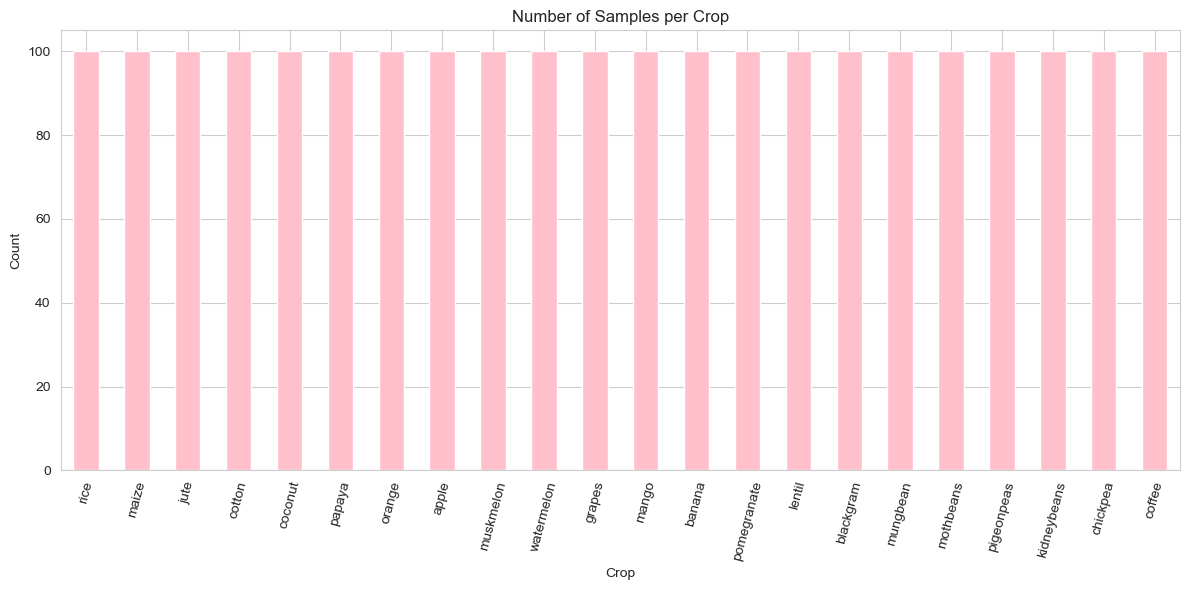

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


In [6]:
plt.figure(figsize=(12, 6))
df['label'].value_counts().plot(kind='bar', color='pink')
plt.title("Number of Samples per Crop")
plt.xlabel("Crop")
plt.ylabel("Count")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

print(df['label'].value_counts())

## 3. Univariate Analysis
Distribution of each numeric feature.

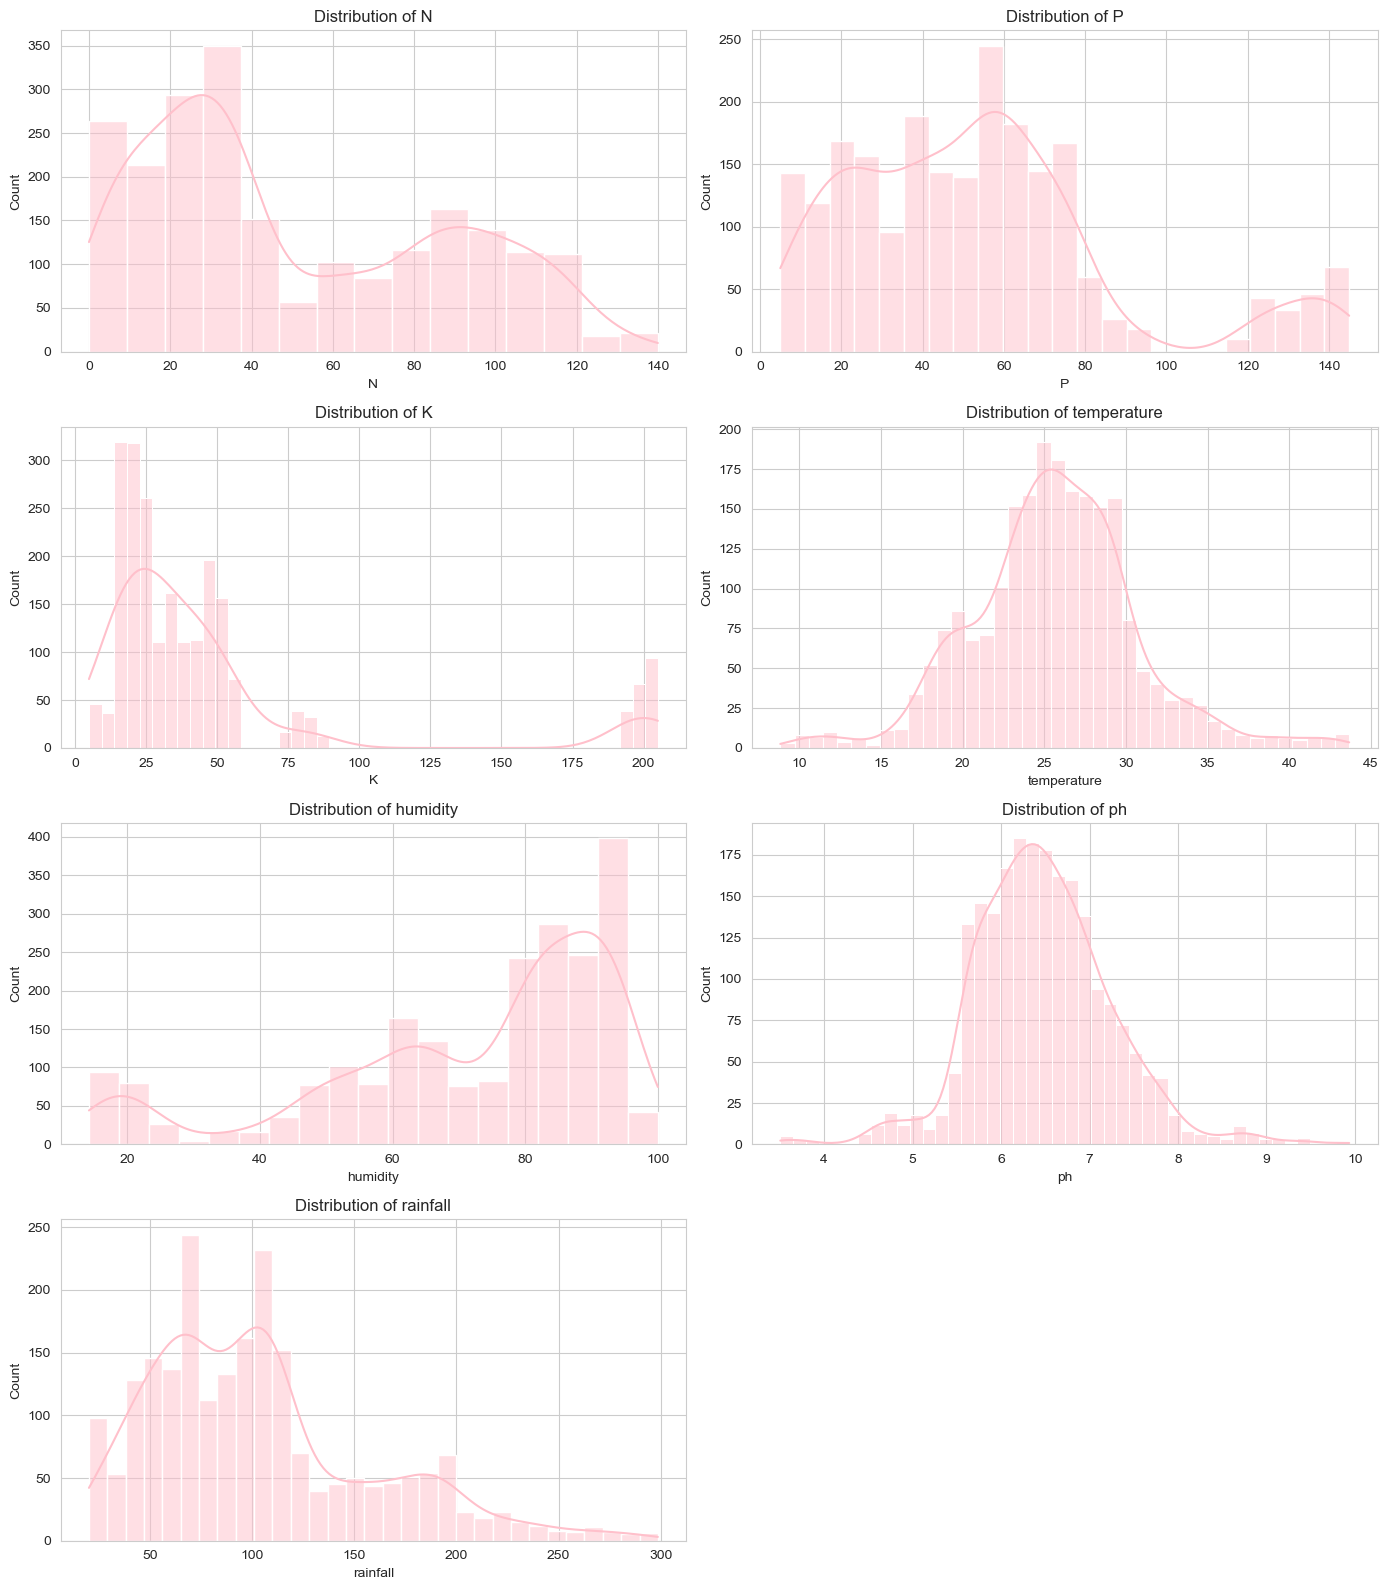

In [8]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='pink')
    axes[i].set_title(f"Distribution of {col}")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

In [9]:
# Skewness check
print(df[features].skew().sort_values(ascending=False))

K              2.375167
P              1.010773
rainfall       0.965756
N              0.509721
ph             0.283929
temperature    0.184933
humidity      -1.091708
dtype: float64


## 4. Class-wise Feature Analysis
How each feature varies across crops — this is the core agronomic insight.

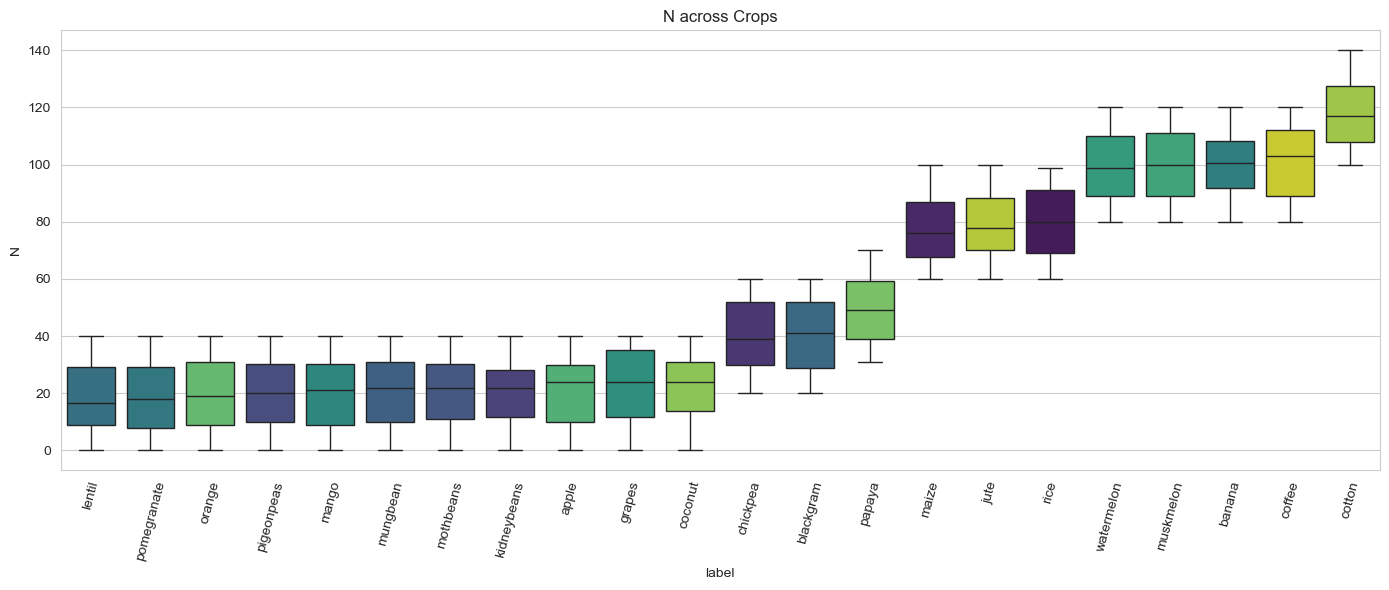

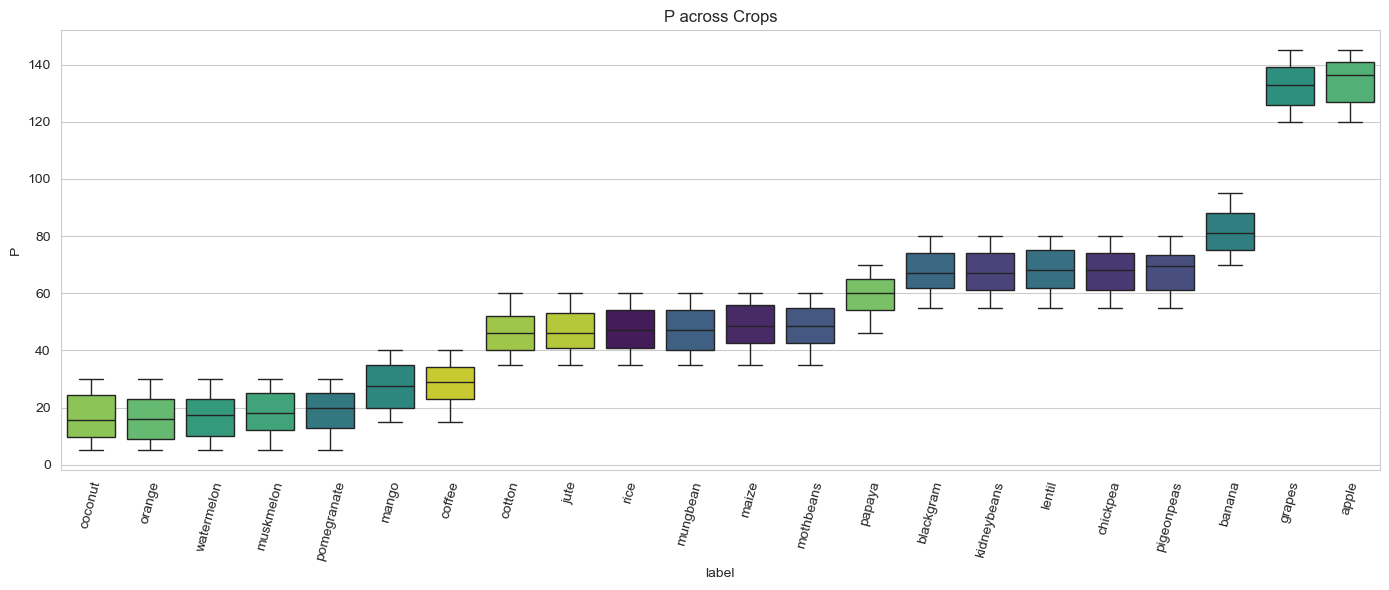

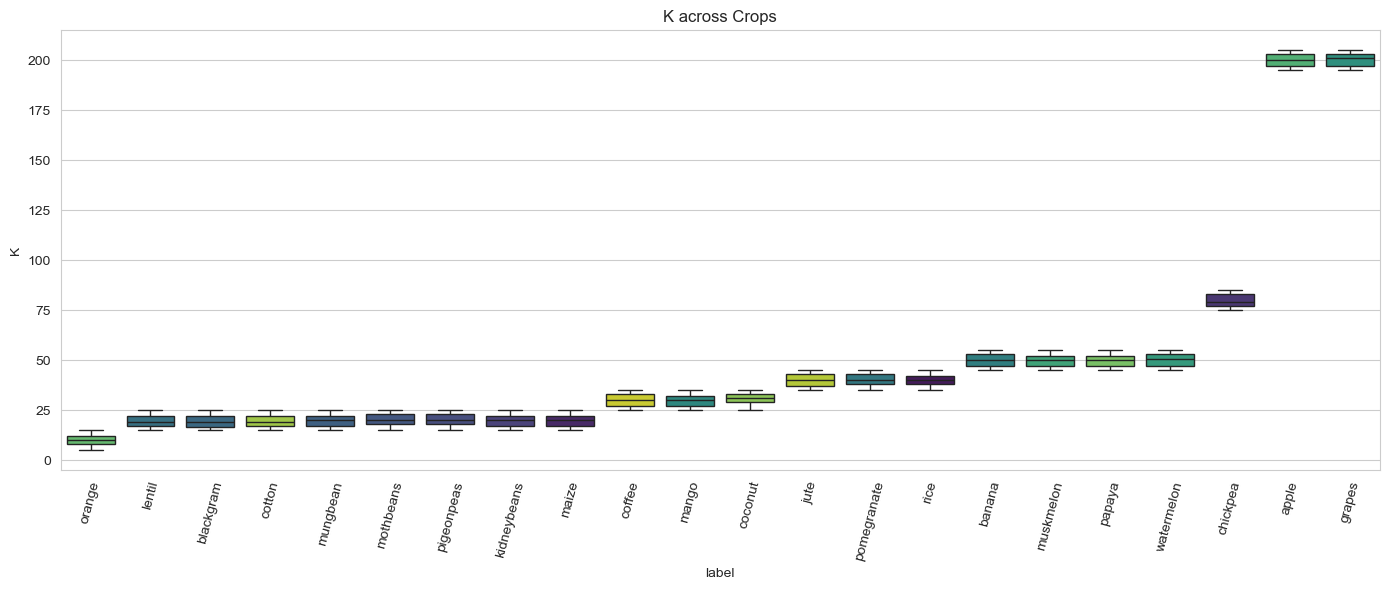

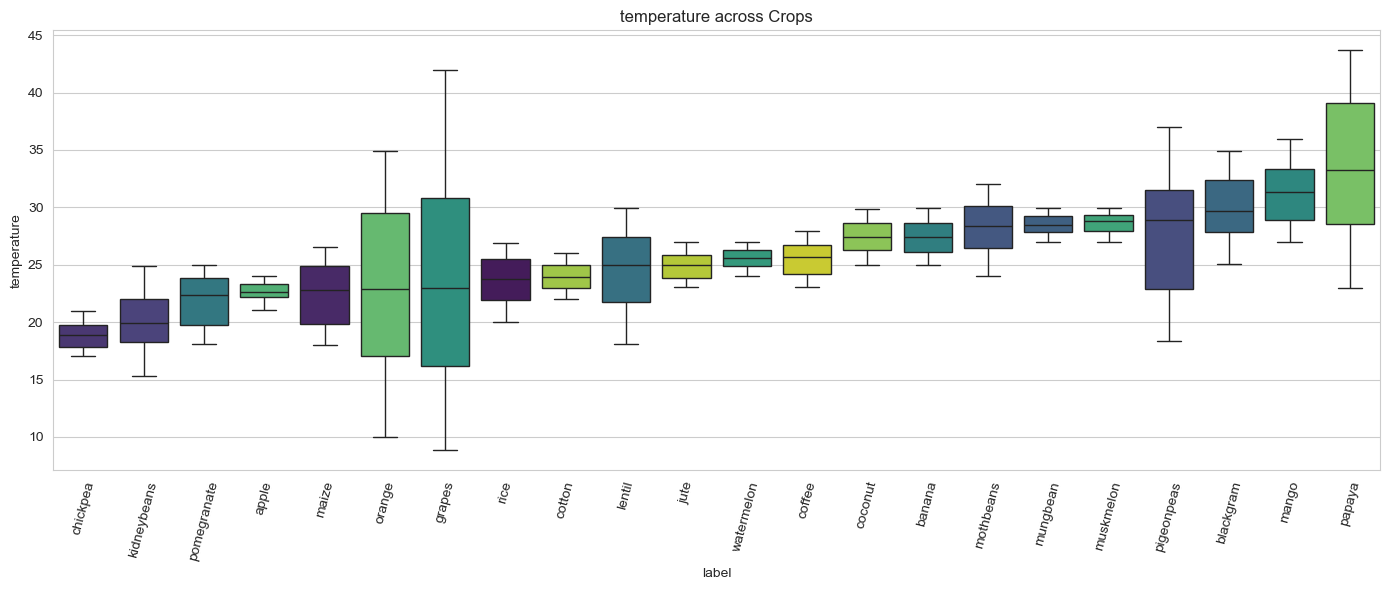

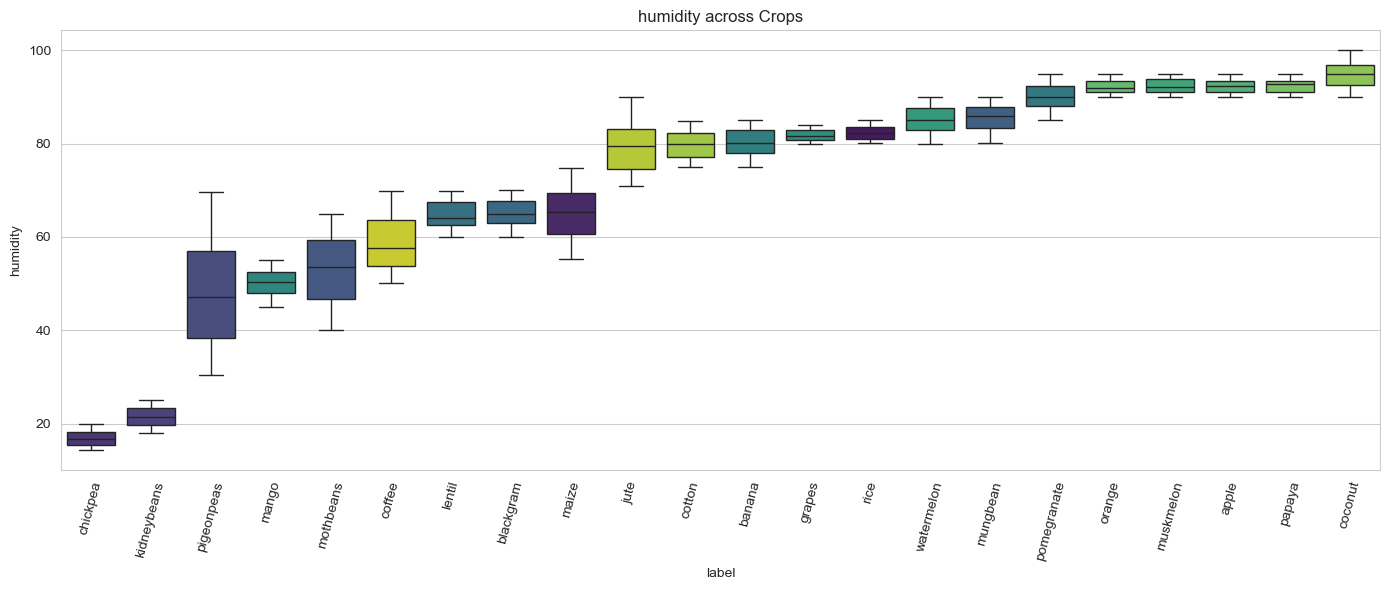

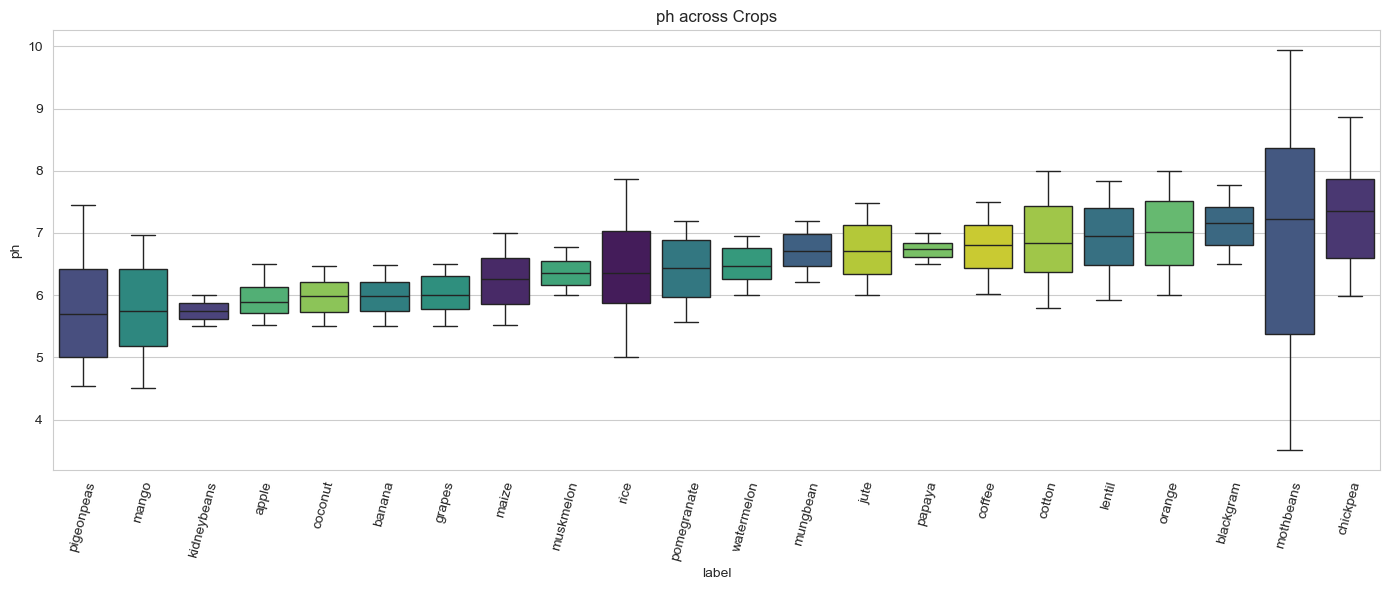

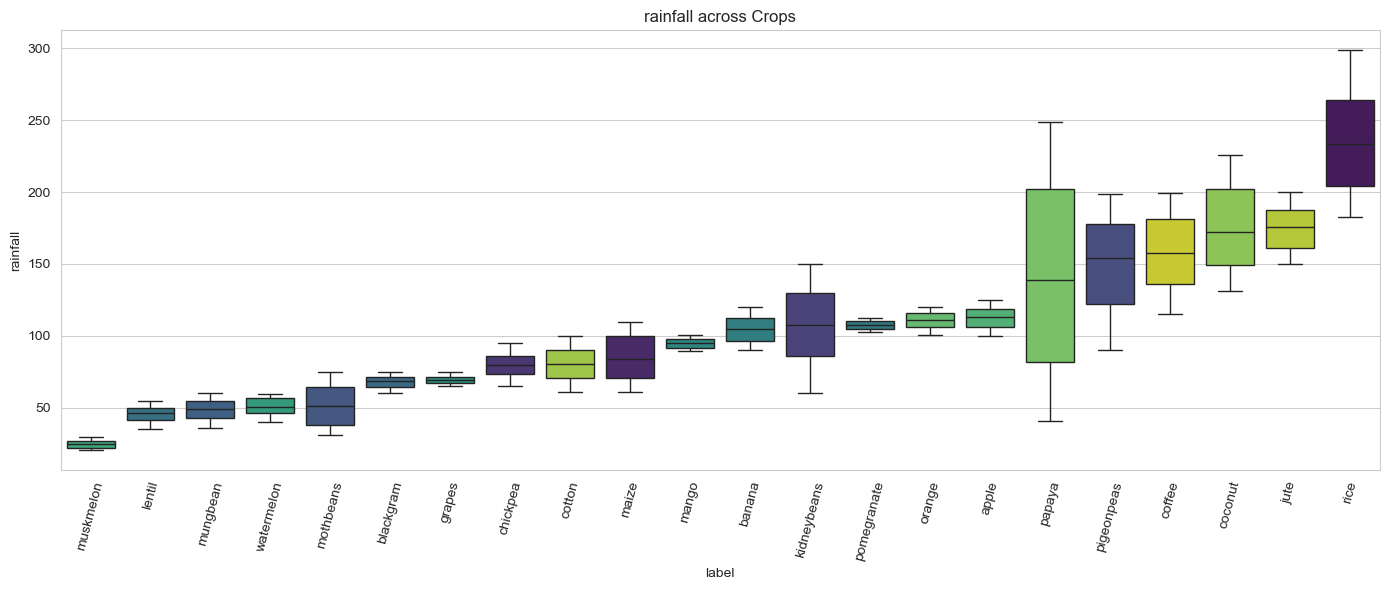

In [12]:
for col in features:
    plt.figure(figsize=(14, 6))
    order = df.groupby('label')[col].median().sort_values().index
    sns.boxplot(data=df, x='label', y=col, order=order, hue='label', 
                palette='viridis', legend=False)
    plt.title(f"{col} across Crops")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.show()

Focus on N, P, K individually since these map directly to fertilizer recommendations later.

C:\Users\mywin\AppData\Local\Temp\ipykernel_39976\709582854.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
C:\Users\mywin\AppData\Local\Temp\ipykernel_39976\709582854.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
C:\Users\mywin\AppData\Local\Temp\ipykernel_39976\709582854.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)


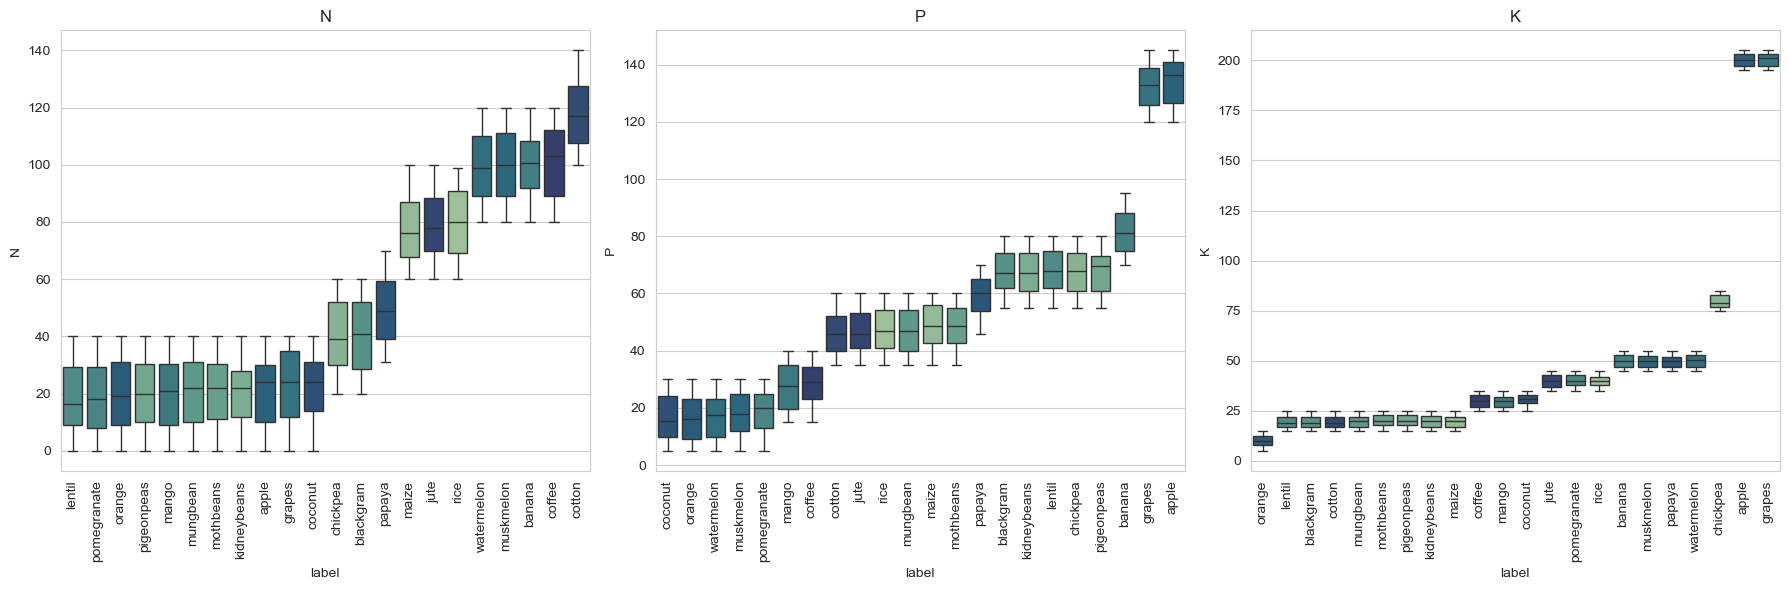

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ['N', 'P', 'K']):
    order = df.groupby('label')[col].median().sort_values().index
    sns.boxplot(data=df, x='label', y=col, order=order, ax=ax, 
                hue='label', palette='crest', legend=False)
    ax.set_xticklabels(order, rotation=90)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

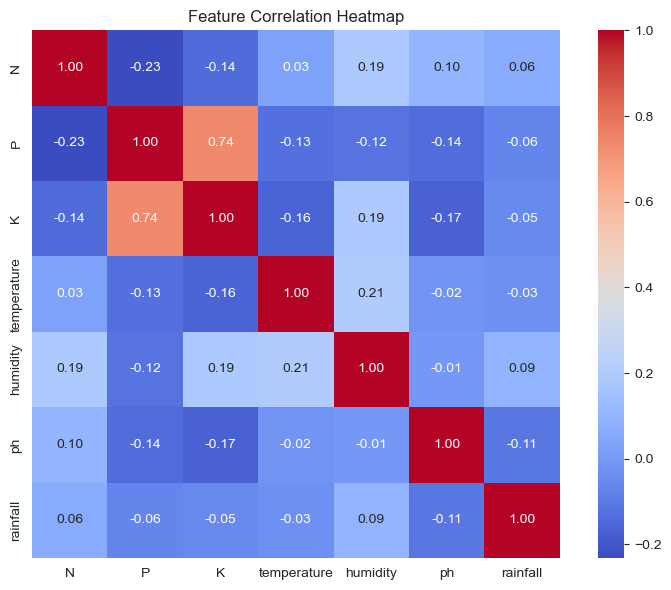

In [14]:
plt.figure(figsize=(8, 6))
corr = df[features].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

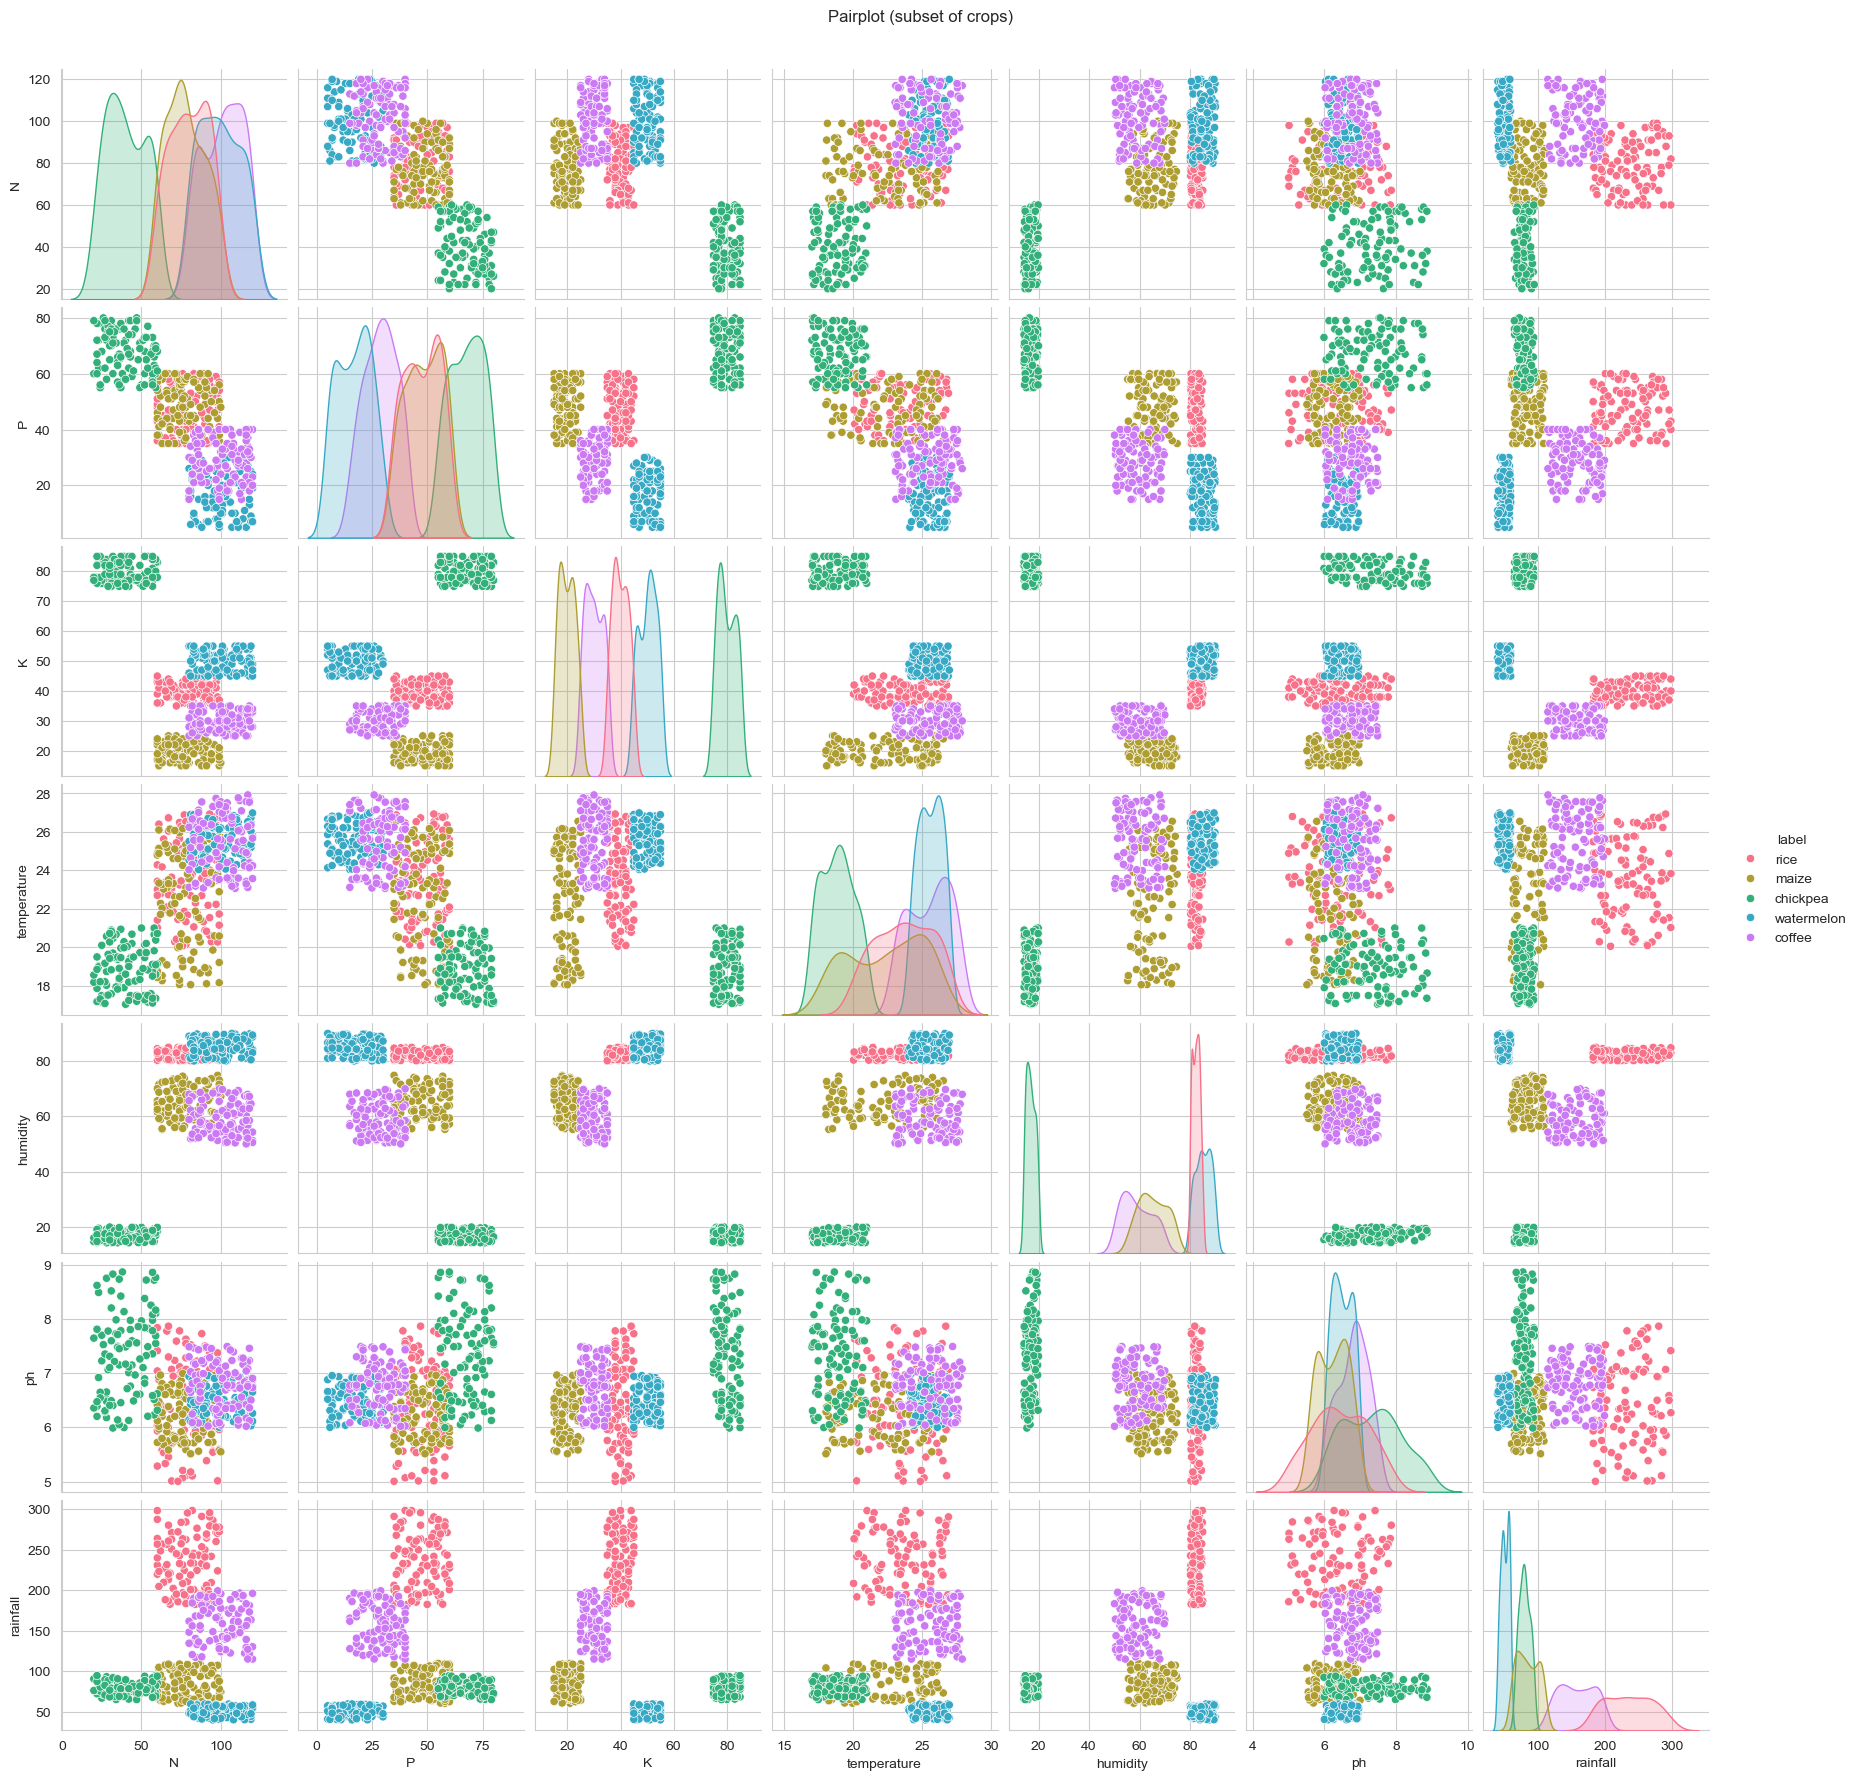

In [15]:
# Pairplot on a subset of crops for readability (full 2200x7 pairplot is heavy/cluttered)
subset_crops = ['rice', 'maize', 'chickpea', 'watermelon', 'coffee']
sns.pairplot(df[df['label'].isin(subset_crops)], hue='label', vars=features, palette='husl', diag_kind='kde')
plt.suptitle("Pairplot (subset of crops)", y=1.02)
plt.show()

## 6. Outlier Check (IQR method)

In [16]:
def iqr_outlier_count(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return ((series < lower) | (series > upper)).sum()

outlier_summary = pd.Series({col: iqr_outlier_count(df[col]) for col in features})
print(outlier_summary.sort_values(ascending=False))

K              200
P              138
rainfall       100
temperature     86
ph              57
humidity        30
N                0
dtype: int64


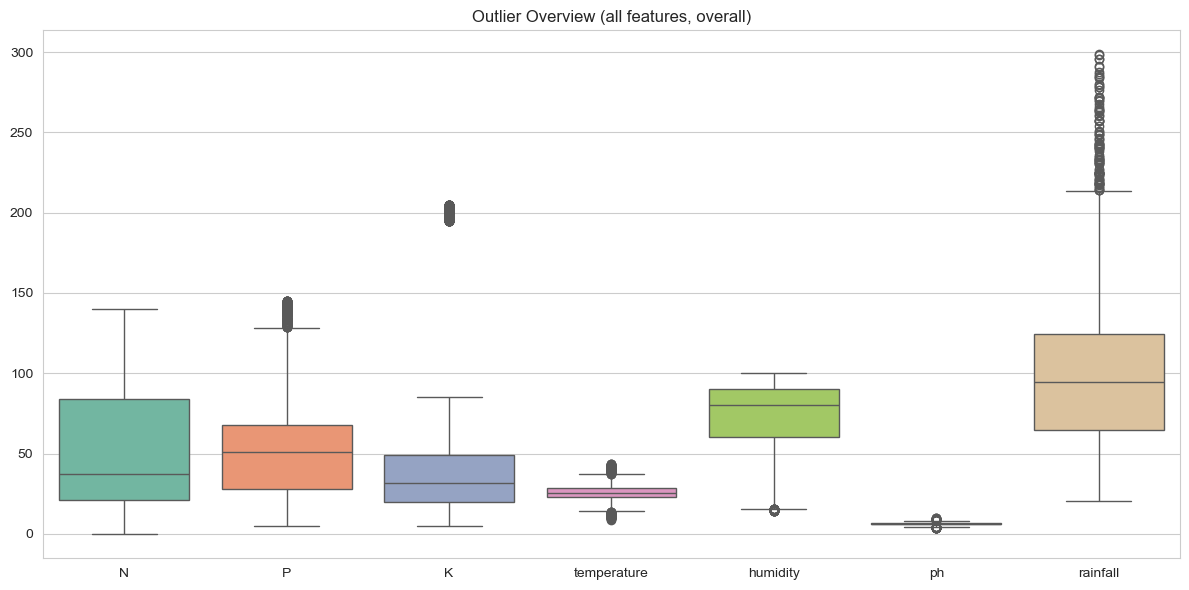

In [17]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[features], palette='Set2')
plt.title("Outlier Overview (all features, overall)")
plt.tight_layout()
plt.show()

# NOTE: In soil/climate data, extreme values are often real agronomic conditions
# (e.g. crops needing very high rainfall) rather than data errors.
# Decision: keep outliers as-is for this project, but document this choice in the report.

## 7. Train/Test Split (Stratified)
Split before scaling to avoid data leakage.

In [18]:
X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nClass balance check (train):")
print(y_train.value_counts().head())

Train shape: (1760, 7)
Test shape: (440, 7)

Class balance check (train):
label
orange         80
grapes         80
coconut        80
papaya         80
pomegranate    80
Name: count, dtype: int64


## 8. Feature Scaling
Needed for Logistic Regression and KNN; harmless for tree models.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 9. Baseline Models
Train Logistic Regression, Decision Tree, Random Forest, and KNN with default/simple params.

In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

results = {}
trained_models = {}

for name, model in models.items():
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    results[name] = {"accuracy": acc, "macro_f1": f1}
    trained_models[name] = model
    print(f"{name}: accuracy={acc:.4f}, macro_f1={f1:.4f}")

Logistic Regression: accuracy=0.9727, macro_f1=0.9725
Decision Tree: accuracy=0.9795, macro_f1=0.9794
Random Forest: accuracy=0.9955, macro_f1=0.9955
KNN: accuracy=0.9795, macro_f1=0.9793


## 10. Model Comparison

In [25]:
results_df = pd.DataFrame(results).T.sort_values("accuracy", ascending=False)
results_df

,accuracy,macro_f1
Random Forest,0.995455,0.995452
Decision Tree,0.979545,0.979423
KNN,0.979545,0.979283
Logistic Regression,0.972727,0.972464


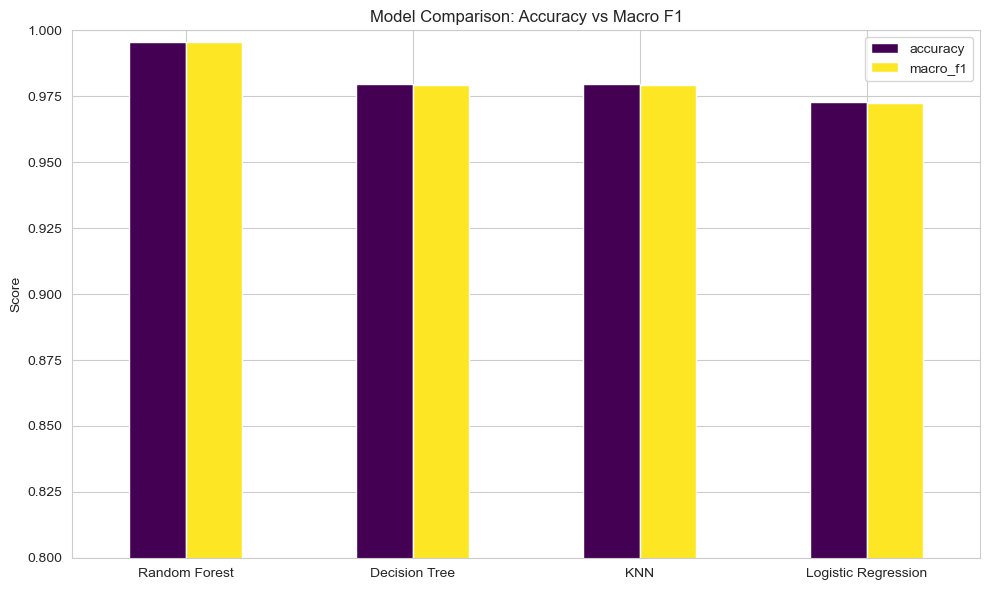

In [26]:
results_df.plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title("Model Comparison: Accuracy vs Macro F1")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0.8, 1.0)
plt.tight_layout()
plt.show()

In [27]:
best_model_name = results_df["accuracy"].idxmax()
best_model = trained_models[best_model_name]
print("Best model:", best_model_name)

if best_model_name in ["Logistic Regression", "KNN"]:
    preds = best_model.predict(X_test_scaled)
else:
    preds = best_model.predict(X_test)

print(classification_report(y_test, preds))

Best model: Random Forest
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
 

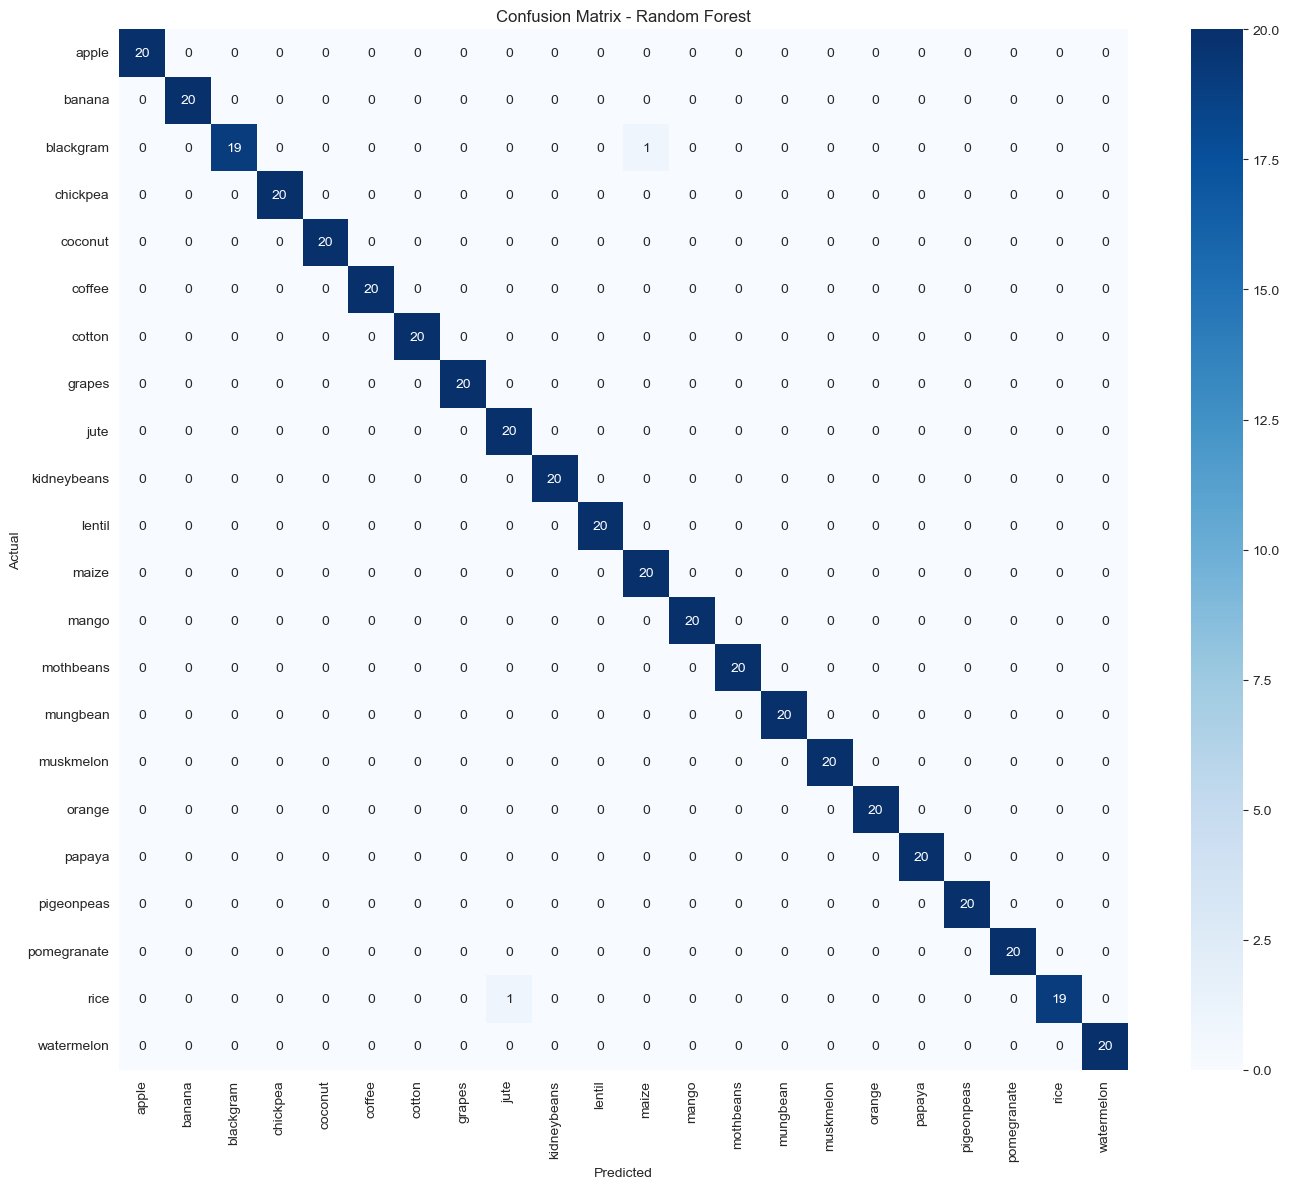

In [28]:
cm = confusion_matrix(y_test, preds, labels=sorted(y.unique()))
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Feature Importance
From Random Forest — ties directly into resource optimization suggestions later.

C:\Users\mywin\AppData\Local\Temp\ipykernel_39976\2342761363.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='mako')


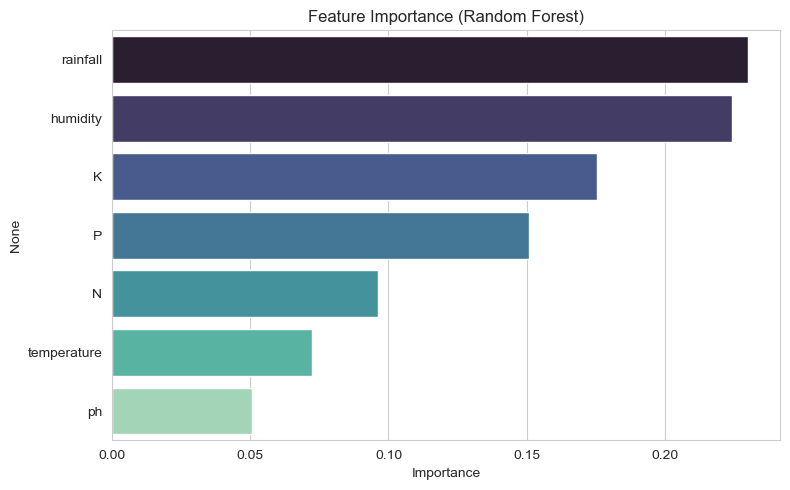

rainfall       0.230184
humidity       0.224227
K              0.175393
P              0.150850
N              0.096363
temperature    0.072375
ph             0.050608
dtype: float64


In [29]:
rf = trained_models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette='mako')
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances)

## 12. Save Best Model
Exports the trained model + scaler for later use in the backend.

In [30]:
joblib.dump(best_model, "crop_model.joblib")
joblib.dump(scaler, "scaler.joblib")

import json
metrics = {
    "best_model": best_model_name,
    "accuracy": results[best_model_name]["accuracy"],
    "macro_f1": results[best_model_name]["macro_f1"],
    "all_results": results
}
with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved crop_model.joblib, scaler.joblib, model_metrics.json")

Saved crop_model.joblib, scaler.joblib, model_metrics.json
